# Assignment 6: Air sensor bias correction model validation

Low-cost air quality sensors are cheap enough to deploy in dense networks, but their raw
readings are not accurate. The usual fix is **calibration**: put the cheap sensor next to a
reference-grade instrument, learn a mapping from one to the other, and apply that mapping
to new readings. That mapping is a machine learning model. Validating it properly is harder
than it looks, and that is the real subject of this assignment.

You will use the dataset of De Vito et al. (2008): five low-cost gas sensors run for about
a year next to reference analyzers in an Italian city.

Answer each numbered question in the empty cell below it.

In [121]:
import io
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

## Load the data

The archive is hosted by the UCI Machine Learning Repository. Missing values are coded
`-200`, which we convert to `NaN` on load. If you leave them in, every model you fit will
be quietly ruined.

In [122]:
url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"
with urllib.request.urlopen(url) as resp:
    archive = zipfile.ZipFile(io.BytesIO(resp.read()))

# European CSV conventions: semicolon separator, comma decimal mark.
aq = pd.read_csv(archive.open("AirQualityUCI.csv"), sep=";", decimal=",",
                 usecols=range(15), na_values=[-200])
aq = aq.dropna(how="all")

aq["datetime"] = pd.to_datetime(
    aq["Date"] + " " + aq["Time"].str.replace(".", ":", regex=False),
    format="%d/%m/%Y %H:%M:%S")
aq = aq.sort_values("datetime").reset_index(drop=True)

print(f"{len(aq)} hourly records, {aq.datetime.min()} to {aq.datetime.max()}")
aq.head()

9357 hourly records, 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


The columns divide into three groups:

- **`PT08.S1` through `PT08.S5`**: the raw responses of the five low-cost sensors.
  These are the cheap instrument.
- **`CO(GT)`, `NMHC(GT)`, `C6H6(GT)`, `NOx(GT)`, `NO2(GT)`**: the co-located reference
  analyzer values. `GT` stands for ground truth. This is what you are trying to predict.
- **`T`, `RH`, `AH`**: temperature, relative humidity, absolute humidity.

We will focus on **NOx**: sensor `PT08.S3(NOx)` against reference `NOx(GT)`.

## Part 1: How bad is the raw sensor?

1) Plot the raw sensor response `PT08.S3(NOx)` against the reference `NOx(GT)` and compute
the correlation. Is the relationship positive or negative? Does it look linear?

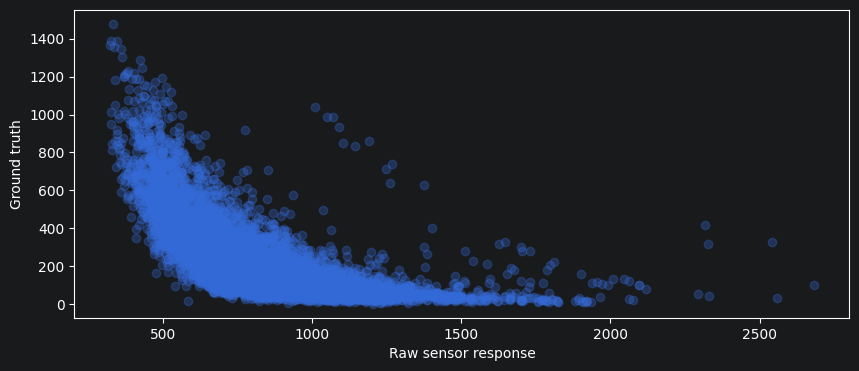

correlation: -0.6557070939270052
The correlation is negative and it does not look linear


In [123]:
fig, ax = plt.subplots(figsize=(10,4))
ax.scatter(aq['PT08.S3(NOx)'], aq['NOx(GT)'], alpha=0.3)
ax.set_xlabel('Raw sensor response')
ax.set_ylabel('Ground truth')
plt.show()

correlation = aq['PT08.S3(NOx)'].corr(aq['NOx(GT)'])
print('correlation: ' + str(correlation))
print('The correlation is negative and it does not look linear')

2) Plot both series against time for a two-week window. Do they track each other?

            Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  \
4950  03/10/2004  00.00.00     NaN       1106.0       NaN       8.5   
4951  03/10/2004  01.00.00     NaN       1037.0       NaN       6.5   
4952  03/10/2004  02.00.00     NaN        982.0       NaN       5.1   
4953  03/10/2004  03.00.00     NaN        944.0       NaN       4.5   
4954  03/10/2004  04.00.00     NaN        929.0       NaN       3.9   
...          ...       ...     ...          ...       ...       ...   
5282  16/10/2004  20.00.00     NaN       1065.0       NaN       7.9   
5283  16/10/2004  21.00.00     NaN       1013.0       NaN       6.2   
5284  16/10/2004  22.00.00     NaN        942.0       NaN       4.0   
5285  16/10/2004  23.00.00     NaN        925.0       NaN       4.4   
5286  17/10/2004  00.00.00     NaN        871.0       NaN       2.6   

      PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  \
4950          921.0      NaN         720.0      NaN        1506.0   
4951     

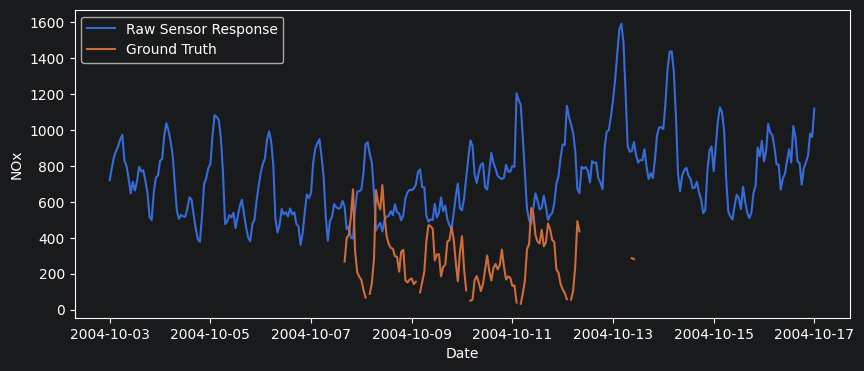

In [124]:
two_week_window = aq[(aq['datetime'] >= '10/03/2004') & (aq['datetime'] <= '10/17/2004')]
print(two_week_window)

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(two_week_window['datetime'], two_week_window['PT08.S3(NOx)'], label='Raw Sensor Response')
ax.plot(two_week_window['datetime'], two_week_window['NOx(GT)'], label='Ground Truth')
ax.set_xlabel('Date')
ax.set_ylabel('NOx')
ax.legend()
plt.show()

3) How many hours have a valid reading for both sensor and reference? What fraction of the deployment is that, and what does the pattern of missingness look like over time?

Total number of readings for the data set is: 9357
Total number of valid readings: 7396
          PT08.S3(NOx)  NOx(GT)
datetime                       
0                  372      336
1                  374      334
2                  375      332
3                  376       26
4                  377      332
5                  377      333
6                  376      334
7                  376      334
8                  376      329
9                  378      334
10                 377      336
11                 376      335
12                 377      335
13                 377      333
14                 374      333
15                 374      334
16                 373      335
17                 371      337
18                 373      336
19                 371      337
20                 373      337
21                 373      336
22                 373      335
23                 372      335
datetime
0     390
1     390
2     390
3     390
4     390
5     390
6     390
7

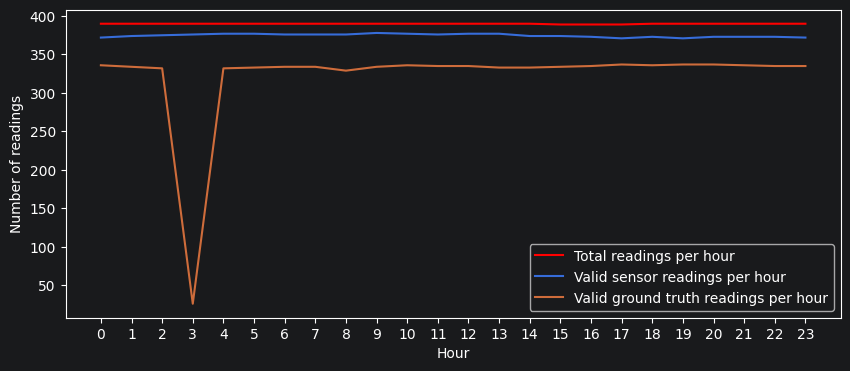

In [125]:
cols = ['PT08.S3(NOx)','NOx(GT)']

print('Total number of readings for the data set is: ' + str(len(aq)))
valid_data = aq[cols].notna().all(axis=1)
print('Total number of valid readings: ' + str(valid_data.sum()))

hour = aq['datetime'].dt.hour
valid_count_by_hour = aq[cols].notna().groupby(hour).sum()
print(valid_count_by_hour)
total_by_hour = aq.groupby(hour).size()
print(total_by_hour)
print('total_by_hour is a constant value of 390 for every hour')

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(total_by_hour.index, total_by_hour.values, color='r', label='Total readings per hour')
ax.plot(valid_count_by_hour.index, valid_count_by_hour['PT08.S3(NOx)'], label='Valid sensor readings per hour')
ax.plot(valid_count_by_hour.index, valid_count_by_hour['NOx(GT)'], label='Valid ground truth readings per hour')
ax.set_xticks(range(24))
ax.set_xlabel('Hour')
ax.set_ylabel('Number of readings')
ax.legend()
plt.show()


In [126]:
print('Sensor readings are missing about 10-20 readings per hour over the entire data set')
print('Ground truth readings are missing about 50-60 readings per hour over the entire data set except for 3am which is missing more than 90% of its readings')

Sensor readings are missing about 10-20 readings per hour over the entire data set
Ground truth readings are missing about 50-60 readings per hour over the entire data set except for 3am which is missing more than 90% of its readings


## Part 2: Baselines

Before fitting anything, establish what has to be beaten.

4) **Baseline 1, raw sensor.** The raw sensor is in the wrong units entirely, so scoring it
directly is meaningless. Instead, fit a single-variable linear regression from
`PT08.S3(NOx)` to `NOx(GT)` on the full dataset, and report RMSE and $R^2$. This is the
simplest possible calibration.

In [127]:
reg = LinearRegression()
X = aq[valid_data][['PT08.S3(NOx)']]
y = aq[valid_data]['NOx(GT)']
reg.fit(X, y)
pred = reg.predict(X)

rmse = np.sqrt(mean_squared_error(y, pred))
print(f"RMSE: {rmse:.2f}")
print(f"R^2:  {r2_score(y, pred):.3f}")

RMSE: 155.76
R^2:  0.430


5) **Baseline 2, predict the mean.** Report the RMSE of always predicting the mean reference NOx. Any model scoring worse than this is worse than useless.

In [106]:
#Climatology - predict using the mean
mean_pred = np.full(len(y), aq[valid_data]['NOx(GT)'].mean())
print('Mean: ' + str(mean_pred[0]))
rmse = np.sqrt(mean_squared_error(y, mean_pred))
print(f"RMSE of predicting mean: {rmse:.2f}")

Mean: 242.18929150892373
RMSE of predicting mean: 206.30


## Part 3: A better correction model

The other sensor channels and the weather variables may also carry information about NOx.
A correction using more inputs should do better.

6) Build a feature matrix from all five `PT08.S*` sensor channels plus `T`, `RH` and `AH`,
with `NOx(GT)` as the target. Drop rows with missing values and report how many remain.

In [101]:
all_variables = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'NOx(GT)', 'datetime']
all_features = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
    all_rows = aq[all_variables].dropna()
X_features = all_rows[all_features]
y_feature = all_rows['NOx(GT)']
print('Number of rows left after dropping rows with missing values: ' + str(len(X)))

Number of rows left after dropping rows with missing values: 8991


7) Fit a `RandomForestRegressor` using a **random** train/test split (`random_state=0`). Report RMSE and $R^2$ on the test set.

In [103]:
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0)
forest.fit(X_features, y)
print(f"RMSE for Random Forest Regressor with 100 estimators = {np.sqrt(mean_squared_error(y_feature, forest.predict(X_features))):.4f}")

RMSE for Random Forest Regressor with 100 estimators = 37.8810


8) Compare against both baselines. How much has the correction improved things?

In [104]:
print('Baseline 1 (raw sensor) RMSE: 193.95. Baseline 2 (predict mean) RMSE: 636.48')
print('RMSE of Random Forest Regressor is 37.88. This is about 15% of the average value which is much better.')

Baseline 1 (raw sensor) RMSE: 193.95. Baseline 2 (predict mean) RMSE: 636.48


## Part 4: The validation problem

That test score is almost certainly too good, and this is the heart of the assignment.

These are **hourly measurements**. Air pollution is highly autocorrelated: the NOx
concentration at 3pm is very close to the value at 2pm and at 4pm. A random split scatters
those neighboring hours across training and test, so for almost every test hour the model
has already seen the hours either side of it.

That is not the task. In deployment, you calibrate a sensor over some period and then apply
the correction *going forward*, to hours the model has never seen.

9) Re-split the data **chronologically**: train on the first 70% of the record in time, test
on the last 30%. Fit the same random forest and report RMSE and $R^2$.

In [149]:
print('Since the data is sorted chronologically, we can just do a split')

X_train, X_test, y_train, y_test = train_test_split(X_features, y_feature, test_size =0.3, shuffle=False, random_state=42)

chrono_forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0)
forest.fit(X_train, y_train)
predicted_y = forest.predict(X_test)
print(f"RMSE for Chronologically Split Random Forest Regressor with 100 estimators = {np.sqrt(mean_squared_error(y_test, predicted_y)):.4f}")
print(f"R^2 = {r2_score(y_test, predicted_y):.3f}")



Since the data is sorted chronologically, we can just do a split
RMSE for Chronologically Split Random Forest Regressor with 100 estimators = 95.8582
R^2 = 0.792


10) Report both scores side by side. How large is the gap between the random split and the chronological split?

In [ ]:
print('Random split: 37.8810, Chronological split: 95.8582')
print('The chronological split RMSE is about 3x that of the random split')

11) Now do the same comparison for the simple linear calibration from question 4. Is the gap as large? Explain why a flexible model is more vulnerable to this than a rigid one.

In [129]:
chrono_reg = LinearRegression()
chrono_reg.fit(X_train[['PT08.S3(NOx)']], y_train)
pred = chrono_reg.predict(X_test[['PT08.S3(NOx)']])

rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"RMSE: {rmse:.2f}")

print('The RMSE of the chronological linear regression is 161.60. THe RMSE of the linear calibration was 155.76. The difference between the two is a lot less than the random forest regression. The random split for random forest regression has a lot of overfitting because neighboring hours are highly correlated.')

RMSE: 161.60
The RMSE of the chronological linear regression is 161.60. THe RMSE of the linear calibration was 155.76. The difference between the two is a lot less than the random forest regression. Overfitting from the random split affects flexible models more


12) Plot predicted against observed for the chronological test period, as a time series. Does the error grow as you move further from the training period?

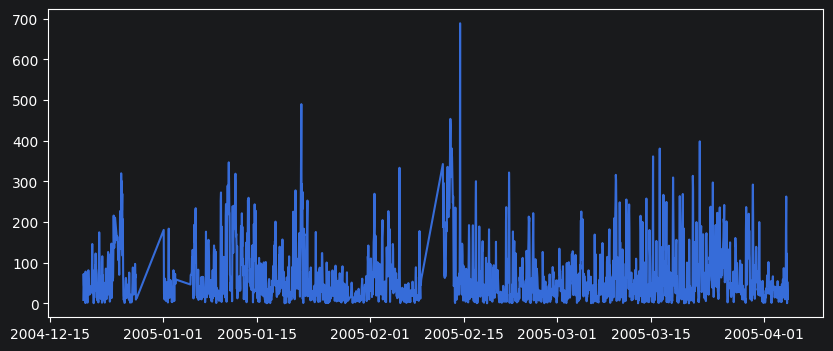

The error does not grow as we get further from the training period. There is a spike in the error around mid february 2025 but no noticeable upward or downward trend.


In [147]:
fig, ax = plt.subplots(figsize=(10,4))
datetime_index = aq.loc[X_test.index, 'datetime']

ax.plot(datetime_index, np.abs(forest.predict(X_test) - y_test), label='Absolute difference of Actual - predicted')
plt.show()

print('The error does not grow as we get further from the training period. There is a spike in the error around mid february 2025 but no noticeable upward or downward trend.')

## Part 5: Report

13) In two or three sentences, state the RMSE and $R^2$ you would report for this model and
which validation scheme produced them.

I would report the RMSE and R2 value from the chronological split version of the Random Forest Regression. It uses the first 70% of data to train the model and then tests on the remaining 30%. This chronological withholding of the test set prevents leakage from neighboring data points from the test set into the training set which can cause overfitting. R2: 0.792; RMSE: 95.8582

```{admonition} A note on what counts as success
:class: tip
If your chronological score is substantially worse than your first random-split score, that is the
correct result and you should report it as such. The purpose of this assignment is to
measure that gap, not to make it disappear.
```